<a href="https://colab.research.google.com/github/tkuttira/Transformers/blob/main/Movie_Recommendation_AI_system.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center><p float="center">
  <img src="https://images.pexels.com/photos/5082566/pexels-photo-5082566.jpeg" width=720></a>
<center><font size=6>Movie Recommendation System</center></font>

# Problem Statement

## Business Context

As a growing player in the Over-The-Top (OTT) streaming market, Streamora, an emerging OTT platform, has recognized the critical need to enhance user engagement through effective content discovery. The platform has implemented a movie recommendation system aimed at helping users find content based on various attributes, including titles, descriptions, and genres. However, analytics from the platform reveal a concerning trend: users frequently overlook these recommendations in favor of manually searching for movies instead. This behavior indicates a potential disconnect between the recommendations provided and the actual preferences of the viewers.

Understanding the underlying reasons for this disconnect is essential for Streamora, as it impacts user satisfaction and engagement on the platform. By improving the recommendation system to align more closely with user interests, Streamora has the opportunity to enhance viewer experience, retain customers, and drive increased viewership across its content library.

##  Objective

The current movie recommendation approach employed by Streamora is not resonating effectively with users, leading to a need for a significant reevaluation and enhancement of the recommendation strategies. To identify what can be improved, Streamora plans to explore alternative recommendation methodologies that better reflect user preferences and behaviors.

The objective is to analyze historical viewer behavior over an 11-month period, focusing on sequences of movies watched by users, and develop and implement a new recommendation engine powered by AI that improves how movies are suggested to users on the Streamora platform. Streamora aims to use the new system to drive user engagement by creating a more personalized viewing experience that resonates with its audience, fostering loyalty and higher content consumption rates.

## Data Description

**Movie Data**

* **title**: Name of the movie.
* **genres**: Space-separated list of genres associated with the movie (e.g., *Action Drama*).
* **overview**: Short summary describing the movie plot or storyline.




**Evaluation Data**

* **movie\_1** to **movie\_7**: Individual columns representing the 7 most recently watched movies by the user.
* **date**: Date on which the evaluation or recommendation is recorded.
* **movie\_watch**: The movie the user actually watched after the recommendation.
* **past_success**: Indicates whether the previous model correctly recommended the watched movie (`True`/`False`).


# Importing Necessary Libraries

Install specific tested library versions to ensure compatibility and avoid errors during development.


In [ ]:
!pip install \
    numpy==1.26.4 \
    scikit-learn==1.6.1\
    scipy==1.13.1\
    gensim==4.3.3 \
    sentence-transformers==3.4.1 \
    gradio==5.33.0\
    pandas==2.2.2

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 4.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 3.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.6/68.6 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 94.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.2/38.2 MB 18.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.6/26.6 MB 73.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.9/275.9 kB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.2/54.2 MB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 323.3/323.3 kB 24.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 444.8/444.8 kB 30.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 78.7 MB/s eta 0:00:00
  Attempting uninstall: pydantic-core
    Found existing installation: pydantic_core 2.41.4
    Uninstalling pydantic_core-2

Note:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [ ]:
import pandas as pd
import numpy as np
from gensim.models import Word2Vec
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import warnings
warnings.filterwarnings('ignore')

In [ ]:
import random

# Set seeds for reproducibility
seed = 42
np.random.seed(seed)
random.seed(seed)

# Loading the Data

We’ll use the Pandas library to load the data. Pandas makes it easy to work with tables of data and take a quick look at what’s inside.

Let’s load the dataset and see what it looks like.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive




<font size=3 color="#4682B4"><b>Alternatively, you can load from Gdrive.
</font>

In [ ]:
movie_data = pd.read_csv('/content/drive/MyDrive/movie_RS/movie_dataset_title.csv')


# Data Overview

## Movie Data

In [ ]:
movie_data.shape

(4803, 3)

The dataset consists of 4803 rows and 3 columns

In [ ]:
movie_data.head(10)


,genres,overview,title
0,Action Adventure Fantasy Science Fiction,"In the 22nd century, a paraplegic Marine is di...",Avatar
1,Adventure Fantasy Action,"Captain Barbossa, long believed to be dead, ha...",Pirates of the Caribbean: At World's End
2,Action Adventure Crime,A cryptic message from Bond’s past sends him o...,Spectre
3,Action Crime Drama Thriller,Following the death of District Attorney Harve...,The Dark Knight Rises
4,Action Adventure Science Fiction,"John Carter is a war-weary, former military ca...",John Carter
5,Fantasy Action Adventure,The seemingly invincible Spider-Man goes up ag...,Spider-Man 3
6,Animation Family,When the kingdom's most wanted-and most charmi...,Tangled
7,Action Adventure Science Fiction,When Tony Stark tries to jumpstart a dormant p...,Avengers: Age of Ultron
8,Adventure Fantasy Family,"As Harry begins his sixth year at Hogwarts, he...",Harry Potter and the Half-Blood Prince
9,Action Adventure Fantasy,Fearing the actions of a god-like Super Hero l...,Batman v Superman: Dawn of Justice


In [ ]:
movie_data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   genres    4775 non-null   object
 1   overview  4800 non-null   object
 2   title     4803 non-null   object
dtypes: object(3)
memory usage: 112.7+ KB


The dataset contains 4,803 movie records with 3 key features:

- title: Movie name — available for all entries.
- overview: Missing in 3 records.
- genres: Missing in 28 records.

In [ ]:
movie_data.dropna(inplace=True)

In [ ]:
movie_data.reset_index(drop=True, inplace=True)

## Evaluation Data

In [ ]:
evaluation_data.shape

(2000, 12)

The dataset consists of 2000 rows and 10 columns

In [ ]:
evaluation_data.head(10)

,movie_1,movie_2,movie_3,movie_4,movie_5,movie_6,movie_7,date,movie_watch,past_success,month_year,word2vec_match
0,The Last Emperor,The Conjuring 2,Conspiracy Theory,Who Killed the Electric Car?,Skyline,No Escape,Big Momma's House,2024-01-01,Urban Legend,True,2024-01,False
1,Face/Off,The Hunger Games: Mockingjay - Part 1,All Good Things,Ray,Extraordinary Measures,Notting Hill,Teeth and Blood,2024-01-01,People I Know,False,2024-01,False
2,The Spectacular Now,Love and Death on Long Island,August Rush,May,Sunday School Musical,Battle of the Year,Broken City,2024-01-01,Peaceful Warrior,True,2024-01,False
3,Ace Ventura: Pet Detective,Joe Dirt,The Cat in the Hat,Roll Bounce,Navy Seals vs. Zombies,The Lost Weekend,Lethal Weapon 3,2024-01-01,RED,False,2024-01,False
4,Pontypool,Up,Reservoir Dogs,Religulous,Blood Work,The Help,Raiders of the Lost Ark,2024-01-01,Cat People,False,2024-01,False
5,National Lampoon's Vacation,The Queen,Carrie,西游记之孙悟空三打白骨精,Obvious Child,Promised Land,Julia,2024-01-01,Robin and Marian,True,2024-01,False
6,Open Range,The Last Shot,The Secret Life of Walter Mitty,East Is East,Phantasm II,Epic,Secret Window,2024-01-02,Shanghai Noon,False,2024-01,False
7,E.T. the Extra-Terrestrial,L!fe Happens,Getaway,Godsend,Hoot,Alive,The Caveman's Valentine,2024-01-02,The Cottage,False,2024-01,False
8,Amnesiac,X-Men: The Last Stand,What to Expect When You're Expecting,Inside Man,De jurk,It's All Gone Pete Tong,Need for Speed,2024-01-02,Dead Man Down,False,2024-01,False
9,Show Boat,The River Wild,Let's Be Cops,Toy Story 2,Rien ne va plus,La sirène du Mississipi,もののけ姫,2024-01-02,Something Wicked,False,2024-01,False


In [ ]:
evaluation_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   movie_1         2000 non-null   object
 1   movie_2         2000 non-null   object
 2   movie_3         2000 non-null   object
 3   movie_4         2000 non-null   object
 4   movie_5         2000 non-null   object
 5   movie_6         2000 non-null   object
 6   movie_7         2000 non-null   object
 7   date            2000 non-null   object
 8   movie_watch     2000 non-null   object
 9   past_success    2000 non-null   bool  
 10  month_year      2000 non-null   object
 11  word2vec_match  2000 non-null   bool  
dtypes: bool(2), object(10)
memory usage: 160.3+ KB


The dataset contains **2000 rows** and includes the following columns:

* **`movie_1` to `movie_7`**: These 7 columns represent recently watched movies by a user. Each column contains movie names as **object** datatype.
* **`movie_watch`**: An **object** datatype column indicating the movie currently being watched.
* **`past_success`**: A **boolean** column indicating whether past recommendations were successful.
* **`date`**: An **object** datatype column representing the date information.

There are **no missing values** in the dataset.


# EDA

In [ ]:

monthly_success_counts = evaluation_data.groupby('month_year')['past_success'].value_counts().unstack(fill_value=0)
monthly_success_counts

past_success,False,True
month_year,,
2024-01,164,22
2024-02,151,23
2024-03,158,28
2024-04,145,35
2024-05,156,30
2024-06,158,22
2024-07,157,29
2024-08,164,22
2024-09,162,18


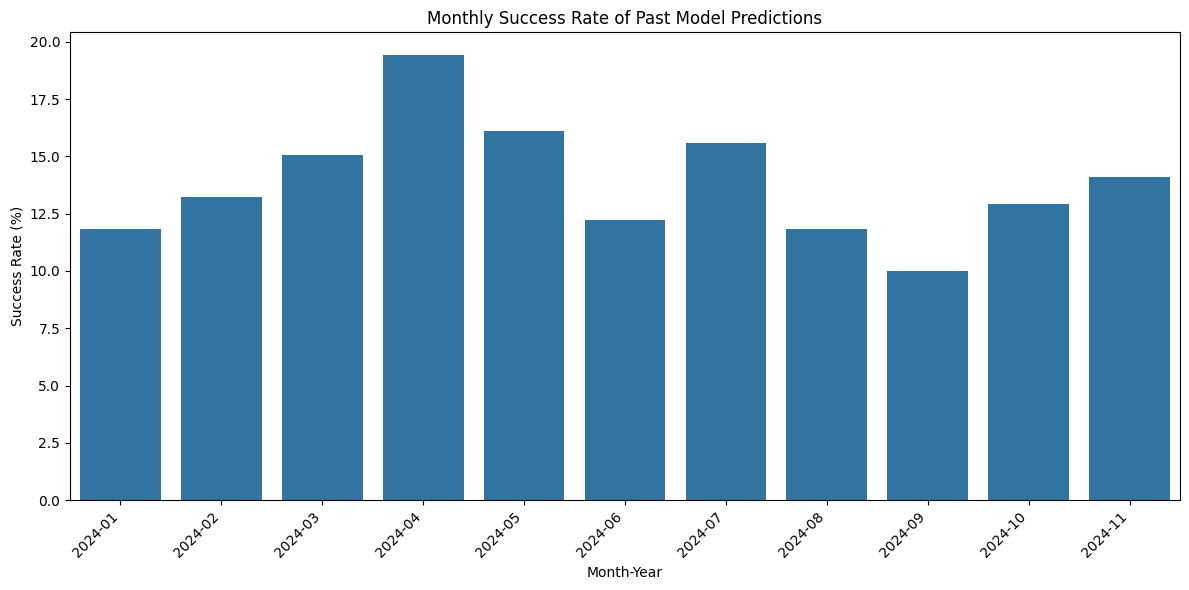

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Convert the 'date' column to datetime objects
# This is necessary to extract month and year information easily.
evaluation_data['date'] = pd.to_datetime(evaluation_data['date'])

# Extract month and year from the 'date' column
# We combine year and month to group data by calendar month across years.
evaluation_data['month_year'] = evaluation_data['date'].dt.to_period('M')

# Group by month and count the occurrences of each 'Past success' value
# This gives us the total count of True and False successes for each month.
monthly_success_counts = evaluation_data.groupby('month_year')['past_success'].value_counts().unstack(fill_value=0)

# Calculate the percentage of 'True' success for each month
# We divide the count of True successes by the total count (True + False) for that month and multiply by 100.
monthly_success_counts['Success Percentage'] = (monthly_success_counts[True] / (monthly_success_counts[True] + monthly_success_counts[False])) * 100

# Sort the data by month and year
# This ensures the plot displays the months in chronological order.
monthly_success_counts = monthly_success_counts.sort_index()

# Create the plot
# We use seaborn for a visually appealing bar plot.
plt.figure(figsize=(12, 6)) # Set the size of the figure for better readability
sns.barplot(x=monthly_success_counts.index.astype(str), y='Success Percentage', data=monthly_success_counts) # Create a bar plot with month_year on x-axis and Success Percentage on y-axis. Use a colormap 'viridis'.

# Add labels and title to the plot
plt.xlabel('Month-Year') # Label for the x-axis
plt.ylabel('Success Rate (%)') # Label for the y-axis
plt.title('Monthly Success Rate of Past Model Predictions') # Title of the plot
plt.xticks(rotation=45, ha='right') # Rotate x-axis labels for better readability, especially if there are many months
plt.tight_layout() # Adjust layout to prevent labels from overlapping

# Display the plot
plt.show()

**Observation:**

The success rate of past model recommendations varies **between 10% and 19.4%** across the months.

* The **highest success rate** was observed in **April 2024 (\~19.4%)**, indicating peak performance of the past recommendation model.
* The **lowest success rate** was recorded in **September 2024 (\~10%)**, showing a drop in effectiveness.


In [ ]:
# .sum(): This adds up all the values in the past_success column. In the case of binary data (1s and 0s), the sum is equal to the total count of successful entries.

overall_success_percentage = (evaluation_data['past_success'].sum() / len(evaluation_data)) * 100
len(evaluation_data)

evaluation_data['past_success']


,past_success
0,True
1,False
2,True
3,False
4,False
...,...
1995,False
1996,False
1997,False
1998,False


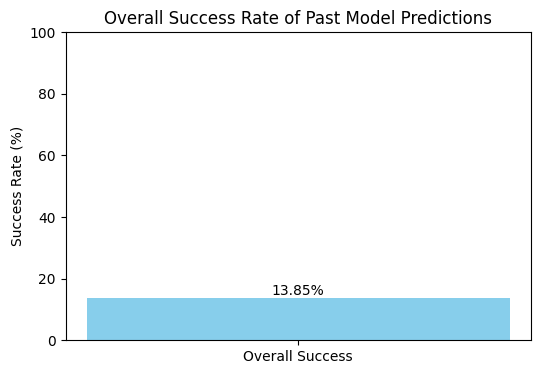

In [ ]:
# Calculate the overall success percentage
overall_success_percentage = (evaluation_data['past_success'].sum() / len(evaluation_data)) * 100

# Create a figure and an axes
fig, ax = plt.subplots(figsize=(6, 4))

# Create a bar plot for overall success
ax.bar(['Overall Success'], [overall_success_percentage], color='skyblue')

# Add the percentage value on top of the bar
ax.text('Overall Success', overall_success_percentage + 1, f'{overall_success_percentage:.2f}%', ha='center')

# Add labels and title
ax.set_ylabel('Success Rate (%)')
ax.set_title('Overall Success Rate of Past Model Predictions')
ax.set_ylim(0, 100) # Set y-axis limit to 0-100%

# Display the plot
plt.show()

**Observation**

- The past model achieved a 13.85% success rate in recommending movies that were actually watched.


# Model Building

In this project, i experiment with **two different approaches** to generate vector representations of movie metadata:

1. **Word2Vec-based model** – which learns word-level embeddings from tokenized text inputs.
2. **Sentence Transformer-based model** – which captures semantic meaning at the sentence level using pre-trained transformer architectures.

These embeddings will serve as the foundation for calculating movie-to-movie similarity and powering our recommendation system.

Let’s begin by preparing the data and training the first embedding model.


## Word2Vec

**Word2Vec** is a technique that converts words into vector representations based on their contextual relationships in text. These word embeddings capture semantic meaning and can be averaged to represent longer pieces of text like movie descriptions.


**Process of Building a Word2Vec-Based Recommendation System**

1. **Text Preparation**
   Combine the relevant textual fields—**title**, **genres**, and **overview**—into a single string for each movie. Preprocess this combined text by tokenizing, lowercasing, and removing stopwords or punctuation to prepare it for model training.

2. **Model Training**
   Train a Word2Vec model on the preprocessed tokens. This model learns vector representations for each word based on their co-occurrence patterns in the corpus.

3. **Average Vector Calculation**
   Define a function to compute the average Word2Vec embedding for any given text. This is done by averaging the vectors of all valid tokens present in the trained vocabulary.

4. **Embedding Computation**
   For each movie, compute a **single embedding** by taking the average of the word vectors from the combined text (title + genres + overview).

5. **Generating Recommendations**
   To recommend movies:

   * Take the list of recently watched movies by a user.
   * Compute the average embedding of these movies using their content embeddings.
   * Calculate cosine similarity between this average vector and all other movie embeddings.
   * Return the top-ranked movies that are most similar to the user's recent viewing history.


### Model Building

#### <font size=4>**Step 1: Text Preperation**

Combines important text fields (like title, genre, and description) and cleans them by removing punctuation, stopwords, and converting everything to lowercase. This helps the model focus on the actual content.

**Note** We created `data_word2vec` to store tokens, embeddings independently without modifying the original DataFrame.


In [ ]:
#making a copy of the dataset
data_word2vec=movie_data.copy()
data_join=movie_data.copy()

**NOTE:** The `simple_preprocess` function from `gensim.utils` tokenizes the text, lowercases all words, and removes punctuation and very short tokens. It prepares the text for training the Word2Vec model by converting it into a clean list of meaningful words.


In [ ]:
data_join['text'] = data_word2vec['title'] + ' ' + data_word2vec['genres'] + ' ' + data_word2vec['overview']
data_join.head()

,genres,overview,title,text
0,Action Adventure Fantasy Science Fiction,"In the 22nd century, a paraplegic Marine is di...",Avatar,Avatar Action Adventure Fantasy Science Fictio...
1,Adventure Fantasy Action,"Captain Barbossa, long believed to be dead, ha...",Pirates of the Caribbean: At World's End,Pirates of the Caribbean: At World's End Adven...
2,Action Adventure Crime,A cryptic message from Bond’s past sends him o...,Spectre,Spectre Action Adventure Crime A cryptic messa...
3,Action Crime Drama Thriller,Following the death of District Attorney Harve...,The Dark Knight Rises,The Dark Knight Rises Action Crime Drama Thril...
4,Action Adventure Science Fiction,"John Carter is a war-weary, former military ca...",John Carter,John Carter Action Adventure Science Fiction J...


In [ ]:
from gensim.utils import simple_preprocess
data_word2vec['text'] = data_word2vec['title'] + ' ' + data_word2vec['genres'] + ' ' + data_word2vec['overview']

data_word2vec['tokens'] = data_word2vec['text'].apply(lambda x: simple_preprocess(x))
data_word2vec.head()

,genres,overview,title,text,tokens
0,Action Adventure Fantasy Science Fiction,"In the 22nd century, a paraplegic Marine is di...",Avatar,Avatar Action Adventure Fantasy Science Fictio...,"[avatar, action, adventure, fantasy, science, ..."
1,Adventure Fantasy Action,"Captain Barbossa, long believed to be dead, ha...",Pirates of the Caribbean: At World's End,Pirates of the Caribbean: At World's End Adven...,"[pirates, of, the, caribbean, at, world, end, ..."
2,Action Adventure Crime,A cryptic message from Bond’s past sends him o...,Spectre,Spectre Action Adventure Crime A cryptic messa...,"[spectre, action, adventure, crime, cryptic, m..."
3,Action Crime Drama Thriller,Following the death of District Attorney Harve...,The Dark Knight Rises,The Dark Knight Rises Action Crime Drama Thril...,"[the, dark, knight, rises, action, crime, dram..."
4,Action Adventure Science Fiction,"John Carter is a war-weary, former military ca...",John Carter,John Carter Action Adventure Science Fiction J...,"[john, carter, action, adventure, science, fic..."


* Python `apply()` function is used to apply a function (built-in, custom, or lambda) to each row or column of a DataFrame. It's useful for quickly transforming data without writing loops.

*  Python `lambda()` functions are small, anonymous functions created with the lambda keyword and are useful for quick, throwaway operations without formally defining a function


####<font size=4>**Step 2: Model Training**

Trains the system to understand word meanings based on how often and where words appear together. This helps capture relationships between similar or related terms.

In [ ]:
model_word2vec = Word2Vec(sentences=data_word2vec['tokens'], vector_size=100, window=5, min_count=1, workers=4,seed=4)

**NOTE**: We don't always use a pretrained Word2Vec model because it's trained on general text (like news articles) and may not capture the specific vocabulary, context, or relationships relevant to a particular domain—like movies, medicine, or legal text. In such cases, training on your own data helps create embeddings that better reflect the meanings and similarities important for your task.

Short explanation of Word2Vec hyperparameters used:

* **`sentences`**: Input data — list of tokenized sentences (your `tokens` column).
* **`vector_size=100`**: Size of the word embeddings (each word is represented by a 100-dimensional vector).
* **`window=5`**: Context window size — the number of words before and after a target word to consider for training.
* **`min_count=1`**: Ignores words with total frequency lower than 1 (i.e., includes all words).
* **`workers=4`**: Number of CPU cores used for parallel training.
* **`seed=42`**: Random seed to ensure reproducibility.


#### <font size=4>**Step 3: Average Vector Calculation**

Averages the embeddings of the individual words to provide a unified representation that captures the overall semantic meaning of the sentence by combining the contributions from all words

- Also makes it easier to compare sentences of different lengths as they're all transformed into vectors of the same dimension.

In [ ]:
def get_avg_word_vector(tokens, model):
    vectors = [model.wv[word] for word in tokens if word in model.wv]
    if vectors:
        return np.mean(vectors, axis=0) # Calculate the mean along axis 0 (down the columns)
    else:
        return np.zeros(model.vector_size)


#### <font size=4>**Step 4: Embedding Computation**

Converts each word into a fixed-length vector based on its content. These vectors help the system compare how similar different items are.

In [ ]:
data_word2vec['embedded_vector'] = data_word2vec['tokens'].apply(lambda x: get_avg_word_vector(x, model_word2vec))

In [ ]:
# len(data_word2vec['embedded_vector'][0])
data_word2vec

,genres,overview,title,text,tokens,embedded_vector
0,Action Adventure Fantasy Science Fiction,"In the 22nd century, a paraplegic Marine is di...",Avatar,Avatar Action Adventure Fantasy Science Fictio...,"[avatar, action, adventure, fantasy, science, ...","[0.09173376, -0.26800635, 0.6659792, -0.705013..."
1,Adventure Fantasy Action,"Captain Barbossa, long believed to be dead, ha...",Pirates of the Caribbean: At World's End,Pirates of the Caribbean: At World's End Adven...,"[pirates, of, the, caribbean, at, world, end, ...","[0.21951279, -0.17738973, 0.607065, -0.7128497..."
2,Action Adventure Crime,A cryptic message from Bond’s past sends him o...,Spectre,Spectre Action Adventure Crime A cryptic messa...,"[spectre, action, adventure, crime, cryptic, m...","[0.15007006, -0.14748566, 0.49501997, -0.56774..."
3,Action Crime Drama Thriller,Following the death of District Attorney Harve...,The Dark Knight Rises,The Dark Knight Rises Action Crime Drama Thril...,"[the, dark, knight, rises, action, crime, dram...","[0.12455617, -0.14410953, 0.5238759, -0.542618..."
4,Action Adventure Science Fiction,"John Carter is a war-weary, former military ca...",John Carter,John Carter Action Adventure Science Fiction J...,"[john, carter, action, adventure, science, fic...","[0.13691267, -0.21476951, 0.62827647, -0.67204..."
...,...,...,...,...,...,...
4767,Foreign Thriller,"Adam, a security guard, travels from Californi...",Cavite,"Cavite Foreign Thriller Adam, a security guard...","[cavite, foreign, thriller, adam, security, gu...","[0.1648667, -0.08673988, 0.4527198, -0.5278664..."
4768,Action Crime Thriller,El Mariachi just wants to play his guitar and ...,El Mariachi,El Mariachi Action Crime Thriller El Mariachi ...,"[el, mariachi, action, crime, thriller, el, ma...","[0.17751183, -0.10816212, 0.5614455, -0.631220..."
4769,Comedy Romance,A newlywed couple's honeymoon is upended by th...,Newlyweds,Newlyweds Comedy Romance A newlywed couple's h...,"[newlyweds, comedy, romance, newlywed, couple,...","[0.12074121, -0.2539671, 0.55921865, -0.580790..."
4770,Comedy Drama Romance TV Movie,"""Signed, Sealed, Delivered"" introduces a dedic...","Signed, Sealed, Delivered","Signed, Sealed, Delivered Comedy Drama Romance...","[signed, sealed, delivered, comedy, drama, rom...","[0.16511247, -0.15666604, 0.49910417, -0.54151..."


In this code:
- It calculates the average word vector for each list of tokens using the Word2Vec model.


#### <font size=4>**Step 5: Generating Recommedations**


Using the average embedding of recently watched movies captures the user's general taste. Comparing this with other movies using cosine similarity helps find content that is semantically similar. Excluding already-watched items ensures that the recommendations are fresh and relevant.

In [ ]:
def word2vec_recommendations(recently_watched_titles, data, model, n_recommendations=10):

    # Get embeddings for the recently watched movies
    watched_embeddings = []
    for title in recently_watched_titles:
        movie_row = data[data['title'] == title] #lookup title and place it in data[] list
        if not movie_row.empty:
            watched_embeddings.append(movie_row.iloc[0]['embedded_vector']) #iloc[0] first matching row

    if not watched_embeddings:
        return ["Could not find embeddings for recently watched movies."]


    # Compute the average embedding of the recently watched movies
    avg_watched_embedding = np.mean(watched_embeddings, axis=0)

    # Calculate cosine similarity between the average watched embedding and all movie embeddings
    all_embeddings = np.vstack(data['embedded_vector'].values)

    #  This function calculates the similarity scores between the single vector (avg_watched_embedding) and every vector within the all_embeddings set
    similarities = cosine_similarity([avg_watched_embedding], all_embeddings)[0]


    recommended_indices = similarities.argsort()[::-1] # Sort in descending order

    recommended_titles = []
    for idx in recommended_indices:
        movie_title = data.iloc[idx]['title']
        if movie_title not in recently_watched_titles:
            recommended_titles.append(movie_title)
            if len(recommended_titles) >= n_recommendations:
                break

    return recommended_titles

Let's generate recommendations from the movies we've already watched.

In [ ]:
watched_movies = ['The Avengers', 'Iron Man', 'Man of Steel']
word2vec_recommendations(watched_movies, data_word2vec, model_word2vec,6)


['Stake Land',
 'The Lost Skeleton of Cadavra',
 'John Carter',
 "The Devil's Tomb",
 'Under the Skin',
 'Spawn']

The Word2vec model produced a mix of results. While movies like Under the Skin, Stake Land, and Los cronocrímenes somewhat aligned with superhero themes through sci-fi and thriller elements, many recommendations such as The Lost Skeleton of Cadavra and The Devil's Tomb did not match the tone or genre, indicating weak alignment with the original superhero movies.


### Evaluation

**NOTE:** We create a list of past movies so it can be easily passed into the recommendation function.

In [ ]:
past_movies = evaluation_data[['movie_1', 'movie_2', 'movie_3', 'movie_4', 'movie_5', 'movie_6', 'movie_7']].values.tolist()
past_movies[0:2]

[['The Last Emperor',
  'The Conjuring 2',
  'Conspiracy Theory',
  'Who Killed the Electric Car?',
  'Skyline',
  'No Escape',
  "Big Momma's House"],
 ['Face/Off',
  'The Hunger Games: Mockingjay - Part 1',
  'All Good Things',
  'Ray',
  'Extraordinary Measures',
  'Notting Hill',
  'Teeth and Blood']]

In [ ]:
word2vec_recommendations_list = []
for watched_movies_list in past_movies:
    # Filter out None values from the watched_movies_list
    valid_watched_movies = [movie for movie in watched_movies_list if movie is not None]
    recommendations = word2vec_recommendations(valid_watched_movies, data_word2vec, model_word2vec, n_recommendations=10)
    word2vec_recommendations_list.append(recommendations)

# Print the first few recommendations from the word2vec model
print("Word2Vec Recommendations for the first row:", word2vec_recommendations_list[0])

Word2Vec Recommendations for the first row: ['Penitentiary', 'Six-String Samurai', 'From Russia with Love', 'The Contender', 'Rocky', 'The Three Burials of Melquiades Estrada', 'When a Stranger Calls', 'Good Kill', 'Ex Machina', 'Brick Mansions']


In [ ]:
word2vec_recommendations_list[:1]

[['Penitentiary',
  'Six-String Samurai',
  'From Russia with Love',
  'The Contender',
  'Rocky',
  'The Three Burials of Melquiades Estrada',
  'When a Stranger Calls',
  'Good Kill',
  'Ex Machina',
  'Brick Mansions']]

In [ ]:
evaluation_data['word2vec_match'] = evaluation_data.apply(lambda row: row['movie_watch'] in word2vec_recommendations_list[row.name], axis=1)

result_df = evaluation_data[['date', 'movie_watch', 'word2vec_match']]
result_df

,date,movie_watch,word2vec_match
0,2024-01-01,Urban Legend,False
1,2024-01-01,People I Know,False
2,2024-01-01,Peaceful Warrior,False
3,2024-01-01,RED,False
4,2024-01-01,Cat People,True
...,...,...,...
1995,2024-11-28,The Game Plan,False
1996,2024-11-28,Wild Card,False
1997,2024-11-28,Scrooged,True
1998,2024-11-29,Primary Colors,True


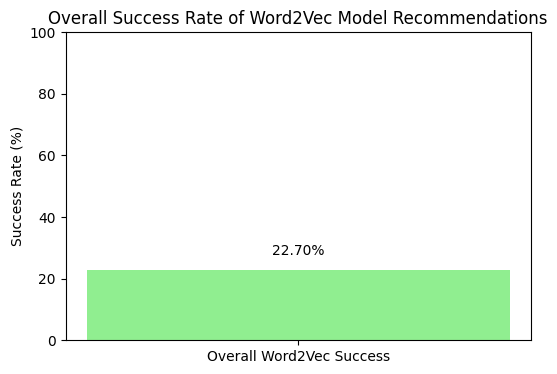

In [ ]:
# Calculate the overall success percentage for Word2Vec
overall_word2vec_success_percentage = (evaluation_data['word2vec_match'].sum() / len(evaluation_data)) * 100

# Create a figure and an axes
fig, ax = plt.subplots(figsize=(6, 4))

# Create a bar plot for overall success
ax.bar(['Overall Word2Vec Success'], [overall_word2vec_success_percentage], color='lightgreen')

# Add the percentage value on top of the bar
ax.text('Overall Word2Vec Success', overall_word2vec_success_percentage +5 , f'{overall_word2vec_success_percentage:.2f}%', ha='center')

# Add labels and title
ax.set_ylabel('Success Rate (%)')
ax.set_title('Overall Success Rate of Word2Vec Model Recommendations')
ax.set_ylim(0, 100) # Set y-axis limit to 0-100%

# Display the plot
plt.show()

**Observation:**
- The Word2Vec model achieves an average recommendation success rate of 23.8%.


**NOTE:** Monthly success refers to the percentage of watched movies that were present in the recommendation list provided by the model. It indicates how effectively the model's recommendations align with actual user behavior.


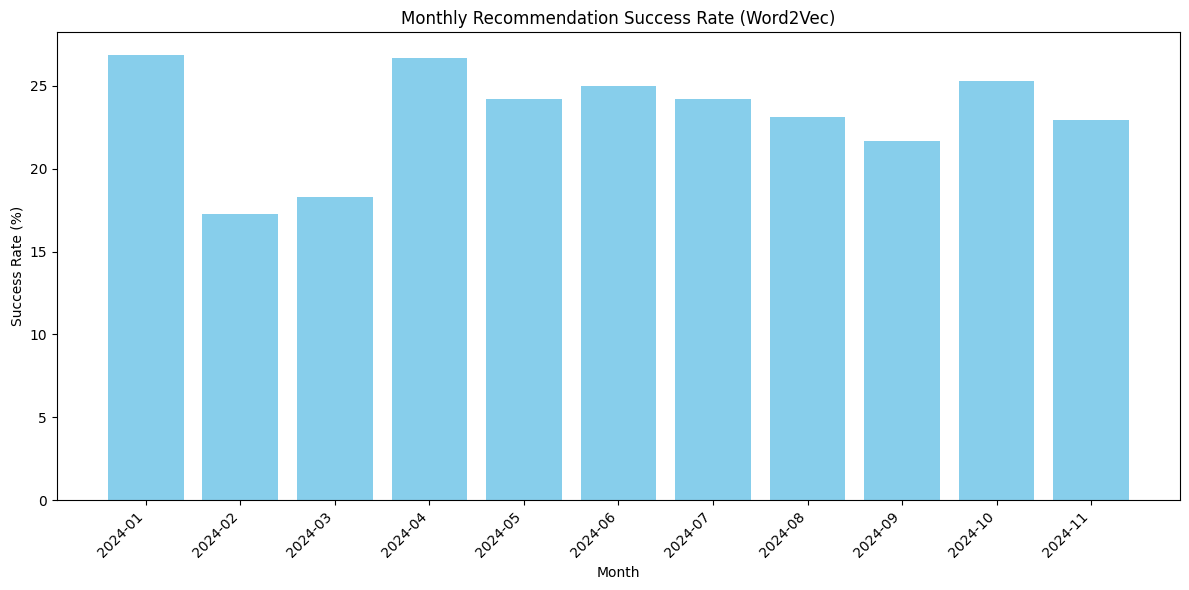

In [ ]:
import matplotlib.pyplot as plt

# Convert 'date' column to datetime objects
result_df['date'] = pd.to_datetime(result_df['date'])

# Extract month and year
result_df['month_year'] = result_df['date'].dt.to_period('M')

# Group by month and count total watches and matches
monthly_summary = result_df.groupby('month_year').agg(
    total_watches=('movie_watch', 'count'),
    successful_recommendations=('word2vec_match', lambda x: (x == True).sum())
).reset_index()

# Calculate success rate
monthly_summary['success_rate'] = (monthly_summary['successful_recommendations'] / monthly_summary['total_watches']) * 100

# Sort by month and year
monthly_summary = monthly_summary.sort_values(by='month_year')

# Convert month_year to string for plotting
monthly_summary['month_year_str'] = monthly_summary['month_year'].astype(str)

# Create the bar chart
plt.figure(figsize=(12, 6))
plt.bar(monthly_summary['month_year_str'], monthly_summary['success_rate'], color='skyblue')
plt.xlabel('Month')
plt.ylabel('Success Rate (%)')
plt.title('Monthly Recommendation Success Rate (Word2Vec)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Observation**

* The **success rate ranges between \~17% and 27%**, indicating moderate performance of the Word2Vec-based recommendation system.
* The **highest success rate** is observed in **April 2024 (\~27%)**.
* The **lowest success rate** occurs in **March 2024 (\~16–17%)**

**Note:** The observations presented are based on the output obtained after training our model. However, since we're using neural network-based architectures here, the results may vary slightly with multiple executions.

## Sentence Transformer

**Sentence Transformers** are models that generate dense vector representations (embeddings) of sentences or texts. These embeddings capture the semantic meaning of the input text, making them suitable for tasks like similarity comparison and recommendation.

**Process of Building a SentenceTransformer-Based Recommendation System**

1. **Creating a Separate Embedding DataFrame**
   We create a new DataFrame, `data_sentf`, to store the SentenceTransformer-based embeddings independently, ensuring the original movie data remains unmodified.

2. **Model Loading**
   Load a pre-trained SentenceTransformer model such as `'all-MiniLM-L6-v2'`, which offers a good balance of performance and efficiency for semantic similarity tasks.

3. **Generating and Storing Combined Embeddings**
   For each movie, compute individual embeddings for the **title**, **genres**, and **overview** using the loaded SentenceTransformer model. Add these embeddings together to form a single combined embedding that captures the movie’s overall content. Store the final embeddings in `data_sentf` for similarity comparison.

4. **Generating Recommendations**
   To generate recommendations:

   * Take a list of movies recently watched by a user.
   * Compute the average embedding of these movies.
   * Calculate cosine similarity between this average embedding and those of all other movies.
   * Return the top-ranked similar movies, excluding those already watched.



### Model Building

#### <font size=4>**Step 1: Creating a Separate Embedding DataFrame**

We created `data_sentf` to store embeddings independently without modifying the original DataFrame.


In [ ]:
data_sentf=movie_data.copy()
data_sentf.head()

,genres,overview,title
0,Action Adventure Fantasy Science Fiction,"In the 22nd century, a paraplegic Marine is di...",Avatar
1,Adventure Fantasy Action,"Captain Barbossa, long believed to be dead, ha...",Pirates of the Caribbean: At World's End
2,Action Adventure Crime,A cryptic message from Bond’s past sends him o...,Spectre
3,Action Crime Drama Thriller,Following the death of District Attorney Harve...,The Dark Knight Rises
4,Action Adventure Science Fiction,"John Carter is a war-weary, former military ca...",John Carter


#### <font size=4>**Step 2: Model Loading**

Using a pre-trained SentenceTransformer model allows us to leverage powerful language understanding without the need to train from scratch. Models like 'all-MiniLM-L6-v2' are optimized for capturing semantic similarity efficiently.

- We use the all-MiniLM-L6-v2 model to generate compact and efficient sentence embeddings suitable for semantic similarity tasks.
- Alternatively, models like **`paraphrase-MpNet-base-v2`** can also be used, though they may require more computational resources.


In [ ]:
model_sentf = SentenceTransformer('all-MiniLM-L6-v2')

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

#### <font size=4>**Step 3: Generating and Storing Combined Embeddings**

Creating embeddings for each text field (title, genres, overview) allows the model to capture different aspects of the content. Adding them together gives a balanced and complete representation. Storing these combined embeddings makes the similarity comparison faster and avoids repeated computation.

In [ ]:

def get_combined_embedding(title, genres, overview, model):
    # Create a combined string
    combined_text = f"{title} {genres} {overview}"
    # Generate embedding for the combined text
    embedding = model.encode(combined_text)

    return embedding

# Apply the function to create embeddings for all movies
data_sentf['embedded_vector'] = data_sentf.apply(
    lambda row: get_combined_embedding(row['title'], row['genres'], row['overview'], model_sentf), axis=1
)

In [ ]:
data_sentf.head()

,genres,overview,title,embedded_vector
0,Action Adventure Fantasy Science Fiction,"In the 22nd century, a paraplegic Marine is di...",Avatar,"[0.008663685, 0.0504747, 0.036730144, -0.03619..."
1,Adventure Fantasy Action,"Captain Barbossa, long believed to be dead, ha...",Pirates of the Caribbean: At World's End,"[-0.036483575, 0.0009981174, -0.08202755, -0.0..."
2,Action Adventure Crime,A cryptic message from Bond’s past sends him o...,Spectre,"[-0.064888984, 0.039840143, -0.029680738, 0.00..."
3,Action Crime Drama Thriller,Following the death of District Attorney Harve...,The Dark Knight Rises,"[-0.014876155, -0.0056883246, -0.08360371, -0...."
4,Action Adventure Science Fiction,"John Carter is a war-weary, former military ca...",John Carter,"[0.0015546484, 0.026247956, -0.006013508, -0.0..."


#### <font size=4>**Step 4: Generating Recommendations**

Using the average embedding of recently watched movies captures the user's general taste. Comparing this with other movies using cosine similarity helps find content that is semantically similar. Excluding already-watched items ensures that the recommendations are fresh and relevant.

In [ ]:
def recommend_movies_sentf(watched_movies_titles, data, model, n=10):

    watched_movies_embeddings = []
    for title in watched_movies_titles:
        movie = data[data['title'] == title]
        if not movie.empty:
            # Use 'combined_embedding' column here
            watched_movies_embeddings.append(movie.iloc[0]['embedded_vector'])


    if not watched_movies_embeddings:
        return []

    # Calculate the average embedding of watched movies
    avg_embedding = np.mean(watched_movies_embeddings, axis=0)

    # Calculate cosine similarity with all other movies using 'combined_embedding'
    similarities = cosine_similarity([avg_embedding], np.vstack(data['embedded_vector'].values))

    # Get the indices of the most similar movies (excluding the watched ones)
    similar_indices = similarities.argsort()[0][::-1]

    recommended_movies = []
    for index in similar_indices:
        movie_title = data.iloc[index]['title'] #Lookup the movie title in the genre data
        if movie_title not in watched_movies_titles:
            recommended_movies.append(movie_title)
        if len(recommended_movies) == n:
            break

    return recommended_movies


Let's generate recommendations from the movies we've already watched.

In [ ]:
last_three = ['The Avengers', 'Iron Man', 'Man of Steel']
res=recommend_movies_sentf(last_three,data_sentf,model_sentf,5)
res

['Iron Man 3',
 'Iron Man 2',
 'Avengers: Age of Ultron',
 'Captain America: Civil War',
 'Steel']

Sentence Transformer model delivered strong, relevant recommendations. Titles like Iron Man 3, Iron Man 2, Avengers: Age of Ultron, and Captain America: Civil War are directly connected to the original superhero universe or share similar themes of action, heroism, and world-building, while Steel also loosely fits the superhero genre. These suggestions show a much better understanding of genre and viewer intent.


### Evaluation

In [ ]:

sentf_recommendations = []
for watched_movies_list in past_movies:
    # Filter out None values from the watched_movies_list
    valid_watched_movies = [movie for movie in watched_movies_list if movie is not None]
    recommendations = recommend_movies_sentf(valid_watched_movies, data_sentf, model_sentf, n=10)
    sentf_recommendations.append(recommendations)

# Print the first few recommendations from the sentence transformer model
print("Sentence Transformer Recommendations for the first row:", sentf_recommendations[0])

Sentence Transformer Recommendations for the first row: ['The Conjuring', 'The Final Destination', 'Unknown', 'Sinister', 'Frailty', 'Insidious', 'Mirrors', 'Crash', 'The Darkest Hour', 'Urban Legend']


In [ ]:
evaluation_data['sentf_match'] = evaluation_data.apply(
    lambda row: row['movie_watch'] in sentf_recommendations[row.name], axis=1
)

result_df = evaluation_data[['date', 'movie_watch', 'sentf_match']]
result_df


,date,movie_watch,sentf_match
0,2024-01-01,Urban Legend,True
1,2024-01-01,People I Know,True
2,2024-01-01,Peaceful Warrior,True
3,2024-01-01,RED,True
4,2024-01-01,Cat People,False
...,...,...,...
1995,2024-11-28,The Game Plan,True
1996,2024-11-28,Wild Card,True
1997,2024-11-28,Scrooged,False
1998,2024-11-29,Primary Colors,False


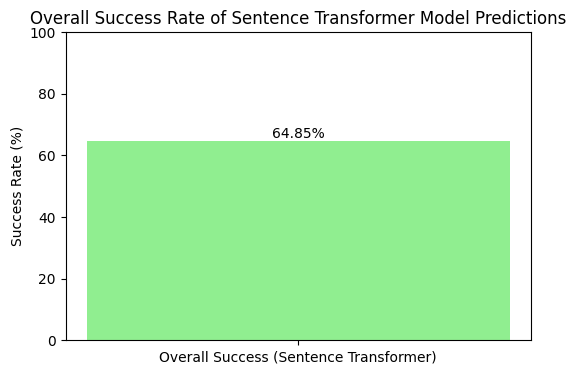

In [ ]:

# Calculate the overall success percentage for the Sentence Transformer model
overall_success_percentage_sentf = (evaluation_data['sentf_match'].sum() / len(evaluation_data)) * 100

# Create a figure and an axes
fig, ax = plt.subplots(figsize=(6, 4))

# Create a bar plot for overall success
ax.bar(['Overall Success (Sentence Transformer)'], [overall_success_percentage_sentf], color='lightgreen')

# Add the percentage value on top of the bar
ax.text('Overall Success (Sentence Transformer)', overall_success_percentage_sentf + 1, f'{overall_success_percentage_sentf:.2f}%', ha='center')

# Add labels and title
ax.set_ylabel('Success Rate (%)')
ax.set_title('Overall Success Rate of Sentence Transformer Model Predictions')
ax.set_ylim(0, 100) # Set y-axis limit to 0-100%

# Display the plot
plt.show()


**Observation:**
- The Sentence Transformer model achieves an average recommendation success rate of 64.85%.


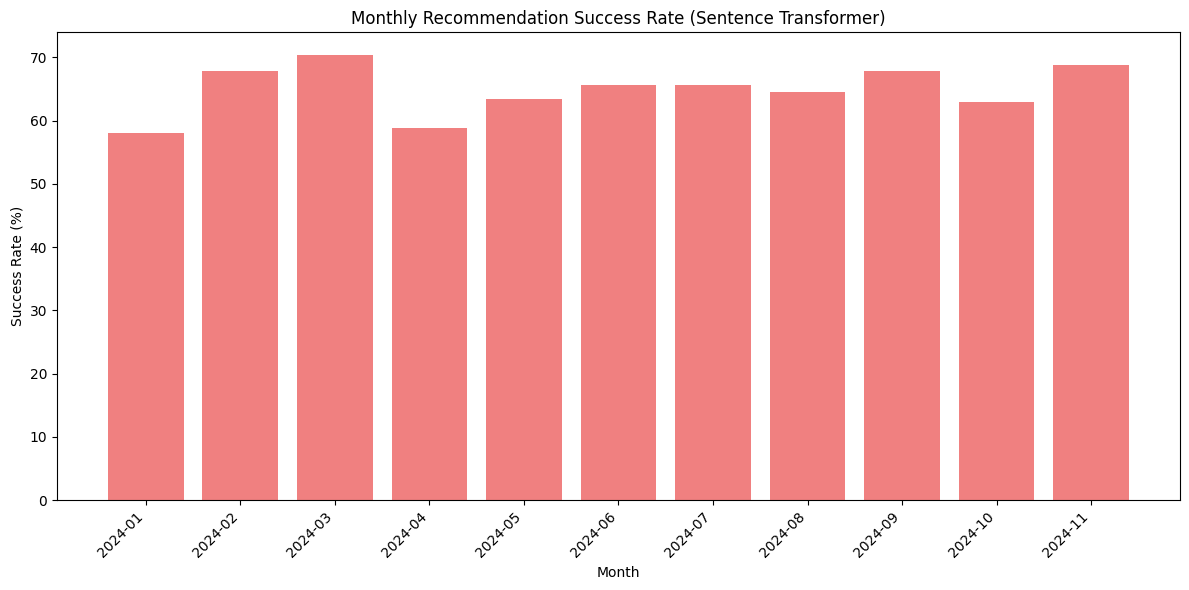

In [ ]:
# Convert 'date' column to datetime objects
result_df['date'] = pd.to_datetime(result_df['date'])

# Extract month and year
result_df['month_year'] = result_df['date'].dt.to_period('M')

# Group by month and count total watches and matches
monthly_summary_sentf = result_df.groupby('month_year').agg(
    total_watches=('movie_watch', 'count'),
    successful_recommendations=('sentf_match', lambda x: (x == True).sum())
).reset_index()

# Calculate success rate
monthly_summary_sentf['success_rate'] = (monthly_summary_sentf['successful_recommendations'] / monthly_summary_sentf['total_watches']) * 100

# Sort by month and year
monthly_summary_sentf = monthly_summary_sentf.sort_values(by='month_year')

# Convert month_year to string for plotting
monthly_summary_sentf['month_year_str'] = monthly_summary_sentf['month_year'].astype(str)

# Create the bar chart
plt.figure(figsize=(12, 6))
plt.bar(monthly_summary_sentf['month_year_str'], monthly_summary_sentf['success_rate'], color='lightcoral')
plt.xlabel('Month')
plt.ylabel('Success Rate (%)')
plt.title('Monthly Recommendation Success Rate (Sentence Transformer)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


**Observation**

* The success rate ranges between **\~58% and 70%**, indicating **strong and consistent performance** of the Sentence Transformer-based recommendation system.
    - This drastic improvement in performance is owing to the fact that Sentence Transformers capture contextual and semantic meaning at the sentence level, unlike Word2Vec which only generates static word-level embeddings.
* The **highest success rate** is observed in **March 2024 (\~69–70%)**.
* The **lowest success rate** occurs in **January 2024 (\~58%)**.
* Most months maintain a success rate above **60%**, showing **robust recommendation quality** across the year.




# Model Comparison

The Sentence Transformer model significantly **outperforms** both:

* The **Word2Vec-based model** (which ranged between \~17% to 27%)
* The **Past recommendation model** (which had lower success percentages overall of ~13.5%)

This demonstrates that **contextually-rich sentence embeddings from transformers** provide a more accurate and reliable basis for generating recommendations.

# Conclusion

- A NLP-based movie recommendation system was successfully developed using two approaches: Word2Vec-based embeddings and Sentence Transformer models, enabling personalized recommendations based on user and movie textual data.

- The Sentence Transformer model demonstrated superior performance in capturing contextual semantics and user preferences, leading to more accurate and relevant movie recommendations.

- Future enhancements may involve incorporating additional user behavior signals, metadata, and fine-tuning Transformer architectures to further improve recommendation quality and user satisfaction.